# Modelado experimental 

In [171]:
import os
import sys

# Agrega el directorio padre (raíz del proyecto) al path de Python
sys.path.append(os.path.abspath(os.path.join('..')))

In [172]:
# ============================================================
# 1. MANIPULACIÓN Y ANÁLISIS DE DATOS
# ============================================================

import numpy as np
import pandas as pd

In [173]:
# ============================================================
# 2. VISUALIZACIÓN DE DATOS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Image

In [174]:
# ============================================================
# 3. PREPROCESAMIENTO Y REDUCCIÓN DE DIMENSIONALIDAD
# ============================================================

from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import KernelPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import trustworthiness

from sklearn.feature_selection import SelectKBest, f_classif, chi2

from umap import UMAP

In [175]:
# ============================================================
# 4. MODELOS DE MACHINE LEARNING
# ============================================================

from sklearn.linear_model import LogisticRegression, SGDClassifier

from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    VotingClassifier,
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    export_text,
    export_graphviz,
    _tree
)

from xgboost import XGBClassifier

In [176]:
# ============================================================
# 5. SELECCIÓN, VALIDACIÓN Y AJUSTE DE MODELOS
# ============================================================

from sklearn.base import clone

from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)

from sklearn.pipeline import Pipeline

In [177]:
# ============================================================
# 6. MÉTRICAS DE EVALUACIÓN
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_recall_curve,
    precision_score,
    PrecisionRecallDisplay,
    r2_score,
    recall_score,
    roc_auc_score,
)
from src.eval_models import eval_model

In [178]:
# ============================================================
# 7. VISUALIZACIÓN DE ÁRBOLES DE DECISIÓN
# ============================================================

import graphviz

In [179]:
# ============================================================
# 8. SISTEMA, UTILIDADES Y SERIALIZACIÓN
# ============================================================

import sys
import os
import pprint
import joblib

In [180]:
# ============================================================
# 9. FUNCIONES Y TRANSFORMACIONES PROPIAS
# ============================================================

from src.custom_standarization_classes_and_functions import GeneralPreprocessor

### Importacion de datos

In [181]:
path_df_processed = '../data/3_gold/df_processed.csv'
df_processed = pd.read_csv(path_df_processed)
df_processed.sample(5)

,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
203,70,Male,Scarf,Accessories,38,Indiana,S,Yellow,Fall,3.2,Yes,Next Day Air,Yes,18,Bank Transfer,Weekly
25,18,Male,Hoodie,Clothing,25,Texas,M,Silver,Summer,3.6,Yes,Express,Yes,14,PayPal,Annually
2875,24,Female,Pants,Clothing,81,Kentucky,M,Pink,Fall,2.6,No,Free Shipping,No,14,Debit Card,Weekly
2316,28,Male,Sneakers,Footwear,39,Montana,L,Yellow,Winter,3.8,No,Standard,No,7,Debit Card,Annually
2207,69,Male,Handbag,Accessories,38,New Mexico,M,Gray,Fall,2.9,No,Next Day Air,No,11,Credit Card,Annually


### Separacion de datos

In [182]:
top_columns = joblib.load('../artifacts/top_columns.joblib')

In [183]:
top_columns

['purchase_amount_usd',
 'review_rating',
 'previous_purchases',
 'promo_code_used',
 'gender',
 'location',
 'shipping_type',
 'payment_method',
 'frequency_of_purchases']

In [184]:
# separo las las variables de la variable target
X = df_processed.drop(columns='Subscription Status').copy()
y = df_processed['Subscription Status'].copy()

In [185]:
y = y.map({'No':0, 'Yes':1})

In [186]:
# Divido las variable target y el resto de variables en testeo y prueba utilizando un 35% de datos para prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

### Instancia y creación de grilla de hiperparámeotros por medio de GridSearchCV

No se observo relaciones o tendencias lineales de manera bivariada. Pero antes de descartar una posible relacion lineal mas alla de combinaciones bivaraiadas, y dada la muestra relativamente chica. Dado el ruido y en general baja seńal observada en el analisis bivariado contra larget, provaremos multiples combinaciones de reducciones lineales y no lineales, al igual que modelos de clasificación robustos y con cierta regularización o robustes ante la varianza en las predicciones.

In [187]:
reduction_options = {
    "Sin reducción": "passthrough",

    "LDA": LinearDiscriminantAnalysis()#,

    #"UMAP": UMAP(
    #   random_state=42
    #)
}

ElasticNet

In [188]:
elasticnet = SGDClassifier(
    loss="log_loss",
    penalty="elasticnet",
    max_iter=3000,
    random_state=42
)

grid_elasticnet = {
    "model__alpha": [0.0001, 0.001, 0.01],
    "model__l1_ratio": [0.2, 0.5, 0.8]
}

SVMLineal

In [189]:
svm_linear = SVC(
    kernel="linear",
    probability=True,
    random_state=42
)

grid_svm_linear = {
    "model__C": [0.1, 1, 10, 100]
}

SVM con kernel RBF

In [190]:
svm_rbf = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

grid_svm_rbf = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

KNN

In [191]:
knn = KNeighborsClassifier()

grid_knn = {
    "model__n_neighbors": [3, 5, 7, 11, 15],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

Arbol individual

In [192]:
decision_tree = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

grid_decision_tree = {
    "model__max_depth": [3, 5, 10, 15],
    "model__min_samples_split": [10, 3, 4, 7, 11],
    "model__min_samples_leaf": [5, 10, 20],
    "model__ccp_alpha": [0.0, 0.001, 0.01]
}

Random Forest

In [193]:
random_forest = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

grid_random_forest = {
    "model__n_estimators": [200, 500],
    "model__max_depth": [None, 10, 7],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.5]
}

XGBoost

In [194]:
xgboost = XGBClassifier(
    random_state=42,
    eval_metric="logloss",
    n_jobs=1
)

grid_xgboost = {
    "model__n_estimators": [200, 500],
    "model__max_depth": [3, 6, 10],
    "model__learning_rate": [0.03, 0.1],
    "model__subsample": [0.8, 1.0]
}

MLPClassifier

In [195]:
mlp = MLPClassifier(
    max_iter=500,
    early_stopping=True,
    random_state=42
)

grid_mlp = {
    "model__hidden_layer_sizes": [
        (50,),
        (100,),
        (100, 50)
    ],
    "model__activation": ["relu", "tanh"],
    "model__alpha": [0.0001, 0.001, 0.01],
    "model__learning_rate_init": [0.001, 0.01]
}

In [196]:
preprocessor = joblib.load('../artifacts/preprocessor.joblib')

In [197]:
pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("reduction", "passthrough"),
    ("model", clone(elasticnet))
])

21 combinaciones / experimentos: Modelos x Hiperparametros x Valores de hiperparametros

In [198]:
models = [
    ("ElasticNet", elasticnet, grid_elasticnet),
    ("SVM lineal", svm_linear, grid_svm_linear),
    ("SVM RBF", svm_rbf, grid_svm_rbf),
    ("KNN", knn, grid_knn),
    ("DecisionTreeClassifier", decision_tree, grid_decision_tree),
    ("Random Forest", random_forest, grid_random_forest),
    ("XGBoost", xgboost, grid_xgboost),
    ("MLPClassifier", mlp, grid_mlp)
]

In [199]:
experiments = []

for model_name, model, model_grid in models:

    for reduction_name, reduction in reduction_options.items():

        params = dict(model_grid)

        params["model"] = [clone(model)]

        if reduction_name == "Sin reducción":
            params["reduction"] = ["passthrough"]

        elif reduction_name == "LDA":
            params["reduction"] = [
                LinearDiscriminantAnalysis()
            ]

        elif reduction_name == "UMAP":
            params["reduction"] = [
                UMAP(random_state=42)
            ]

            params["reduction__n_components"] = [5, 10, 20]
            params["reduction__n_neighbors"] = [10, 15, 30]
            params["reduction__min_dist"] = [0.0, 0.1, 0.5]

        experiments.append({
            "nombre_modelo": model_name,
            "reduccion": reduction_name,
            "param_grid": params
        })

### Entrenamiento y optimización con GridSearchCV

In [200]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [201]:
results = []
best_models = {}
search_objects = {}

for experiment in experiments:

    model_name = experiment["nombre_modelo"]
    reduction_name = experiment["reduccion"]
    params = experiment["param_grid"]
    print(
        f"\nEntrenando {model_name} "
        f"| Reducción: {reduction_name}"
    )

    search = GridSearchCV(
        estimator=clone(pipeline),
        param_grid=params,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        error_score="raise",
        return_train_score=True,
        verbose=0
    )

    search.fit(X, y)

    results.append({
        "Modelo": model_name,
        "Reducción": reduction_name,
        "Mejor AUC CV": search.best_score_,
        "Mejores parámetros": search.best_params_,
        "Desviación AUC CV": search.cv_results_["std_test_score"][
            search.best_index_
        ],
        "AUC entrenamiento": search.cv_results_["mean_train_score"][
            search.best_index_
        ]
    })

    best_models[(model_name, reduction_name)] = search.best_estimator_
    search_objects[(model_name, reduction_name)] = search
    print(f"Mejor AUC CV: {search.best_score_:.4f}")
    print(f"Mejores parámetros: {search.best_params_}")

print("\nExperimentos finalizados.")


Entrenando ElasticNet | Reducción: Sin reducción
Mejor AUC CV: 0.8944
Mejores parámetros: {'model': SGDClassifier(loss='log_loss', max_iter=3000, penalty='elasticnet',
              random_state=42), 'model__alpha': 0.0001, 'model__l1_ratio': 0.2, 'reduction': 'passthrough'}

Entrenando ElasticNet | Reducción: LDA
Mejor AUC CV: 0.8872
Mejores parámetros: {'model': SGDClassifier(loss='log_loss', max_iter=3000, penalty='elasticnet',
              random_state=42), 'model__alpha': 0.0001, 'model__l1_ratio': 0.2, 'reduction': LinearDiscriminantAnalysis()}

Entrenando SVM lineal | Reducción: Sin reducción
Mejor AUC CV: 0.8914
Mejores parámetros: {'model': SVC(kernel='linear', probability=True, random_state=42), 'model__C': 100, 'reduction': 'passthrough'}

Entrenando SVM lineal | Reducción: LDA
Mejor AUC CV: 0.8872
Mejores parámetros: {'model': SVC(kernel='linear', probability=True, random_state=42), 'model__C': 0.1, 'reduction': LinearDiscriminantAnalysis()}

Entrenando SVM RBF | Reducció

In [202]:
df_results = pd.DataFrame(results)

In [203]:
df_results = df_results.sort_values(
    by="Mejor AUC CV",
    ascending=False
).reset_index(drop=True)

df_results

,Modelo,Reducción,Mejor AUC CV,Mejores parámetros,Desviación AUC CV,AUC entrenamiento
0,XGBoost,Sin reducción,0.898783,"{'model': XGBClassifier(base_score=None, boost...",0.007866,0.927643
1,Random Forest,Sin reducción,0.896153,"{'model': RandomForestClassifier(n_jobs=1, ran...",0.006359,0.964412
2,SVM RBF,Sin reducción,0.896148,"{'model': SVC(probability=True, random_state=4...",0.008068,0.902603
3,MLPClassifier,Sin reducción,0.895414,"{'model': MLPClassifier(early_stopping=True, m...",0.014084,0.894089
4,ElasticNet,Sin reducción,0.894443,"{'model': SGDClassifier(loss='log_loss', max_i...",0.015010,0.889957
5,SVM RBF,LDA,0.893260,"{'model': SVC(probability=True, random_state=4...",0.009472,0.890390
6,DecisionTreeClassifier,Sin reducción,0.892918,{'model': DecisionTreeClassifier(class_weight=...,0.008336,0.951685
7,Random Forest,LDA,0.891684,"{'model': RandomForestClassifier(n_jobs=1, ran...",0.010736,0.989237
8,SVM lineal,Sin reducción,0.891360,"{'model': SVC(kernel='linear', probability=Tru...",0.007678,0.892476
9,DecisionTreeClassifier,LDA,0.890346,{'model': DecisionTreeClassifier(class_weight=...,0.008344,0.892178


#### Arbol de desición simple

In [204]:
best_models[('DecisionTreeClassifier', 'Sin reducción')]

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('all_columns', GeneralPreprocessor()),
                                 ('by_data_type_columns',
                                  ColumnTransformer(sparse_threshold=0,
                                                    transformers=[('numeric',
                                                                   'passthrough',
                                                                   ['purchase_amount_usd',
                                                                    'review_rating',
                                                                    'previous_purchases']),
                                                                  ('ordinal',
                                                                   Pipeline(steps=[('encoder',
                                                                                    OrdinalEncoder(categories=[['no',
                                                                                                                'yes'],
                                                                                                               ['annually',
                                                                                                                'quarterly',
                                                                                                                'monthly',
                                                                                                                'bi-weekly',
                                                                                                                'weekly']],
                                                                                                   handle_unknown='use_encoded_value',
                                                                                                   unknown_value=-1))]),
                                                                   ['promo_code_used',
                                                                    'frequency_of_purchases'])]))])),
                ('reduction', 'passthrough'),
                ('model',
                 DecisionTreeClassifier(class_weight='balanced', max_depth=15,
                                        min_samples_leaf=10,
                                        min_samples_split=10,
                                        random_state=42))])

In [218]:
pipeline_decision_tree_sin_reduccion = best_models[('DecisionTreeClassifier', 'Sin reducción')]

In [206]:
decision_tree_sin_reduccion = pipeline_decision_tree_sin_reduccion.named_steps['model']

##### Evaluación 

In [207]:
X_test = pipeline_decision_tree_sin_reduccion.named_steps['preprocessor'].transform(X_test)

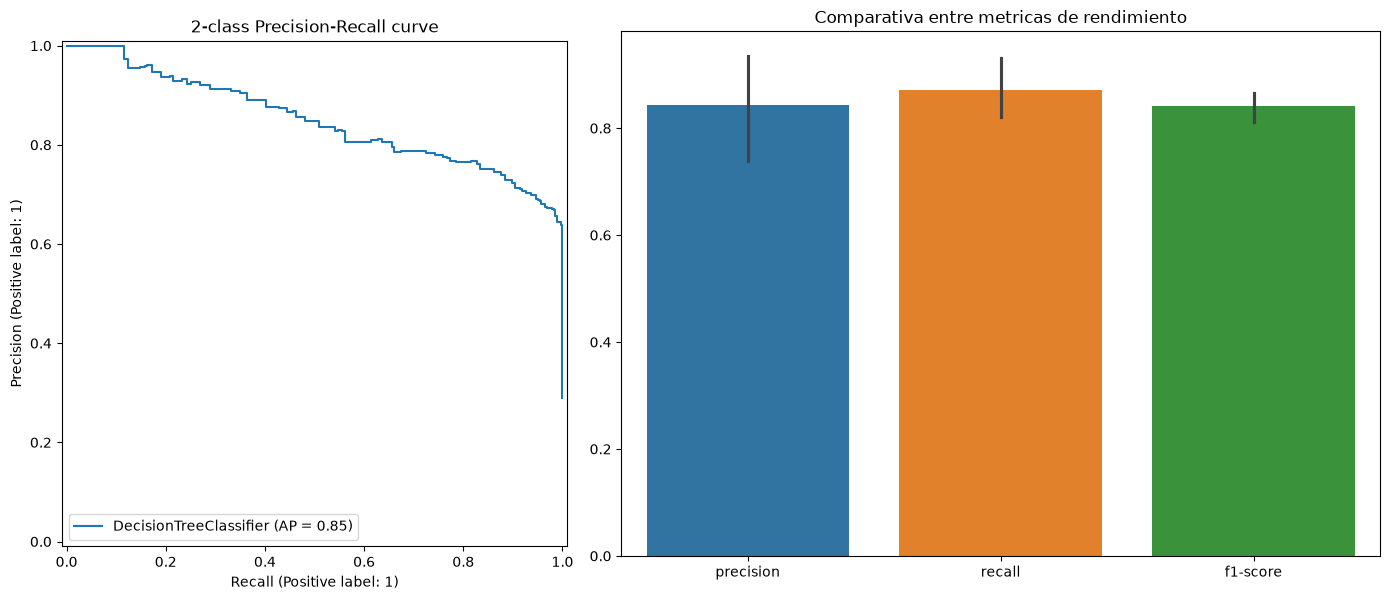

{'y_pred': array([1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1,
        0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1,
        0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0,
        1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
        1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0,
        1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0,
        0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0,
        1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0,
        0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
        1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1,
        0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
        1, 0, 0, 0, 0, 0, 0,

In [208]:
eval_model(is_classification=True, model=decision_tree_sin_reduccion, X=X_test, y=y_test)

##### Interpretabilidad 

In [209]:
nombres_variables = (
    pipeline_decision_tree_sin_reduccion
    .named_steps['preprocessor']
    .get_feature_names_out()
)

In [210]:
# Asociar las clases originales con sus etiquetas

mapa_clases = {
    0: "Usuario tiende a no suscribirse",
    1: "Usuario tiende a suscribirse"
}

# Obtener los nombres respetando el orden de las clases del modelo

nombre_clases = [mapa_clases[clase] for clase in pipeline_decision_tree_sin_reduccion.classes_]

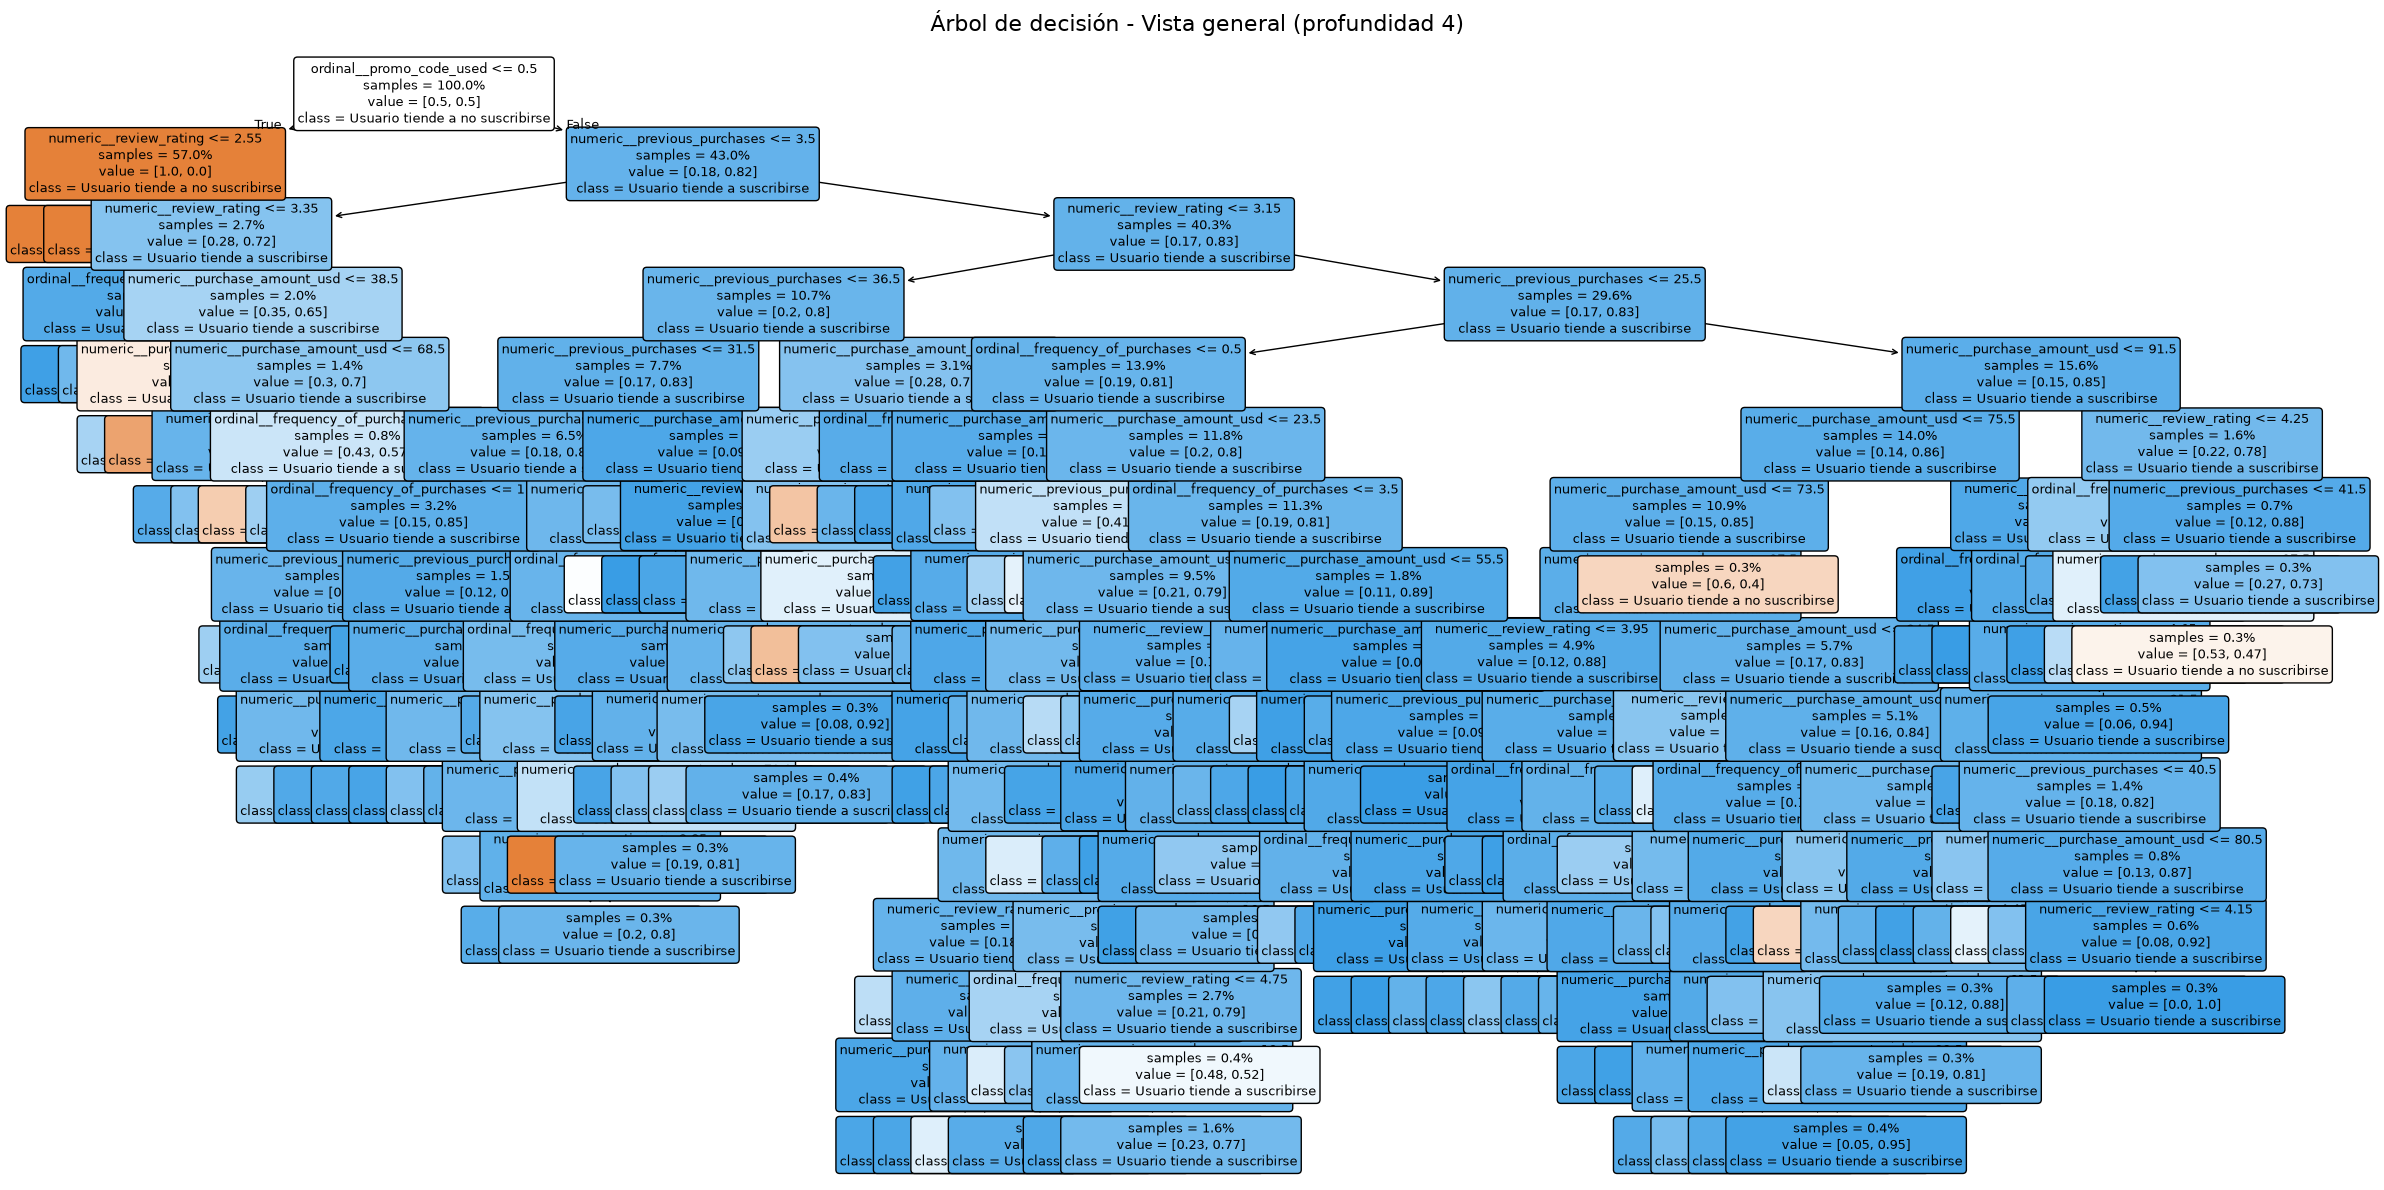

In [211]:
# Crear la figura
fig, ax = plt.subplots(figsize=(24, 12))

plot_tree(
    decision_tree_sin_reduccion,
    max_depth=15,  # Mostrar solo los primeros niveles
    filled=True,
    rounded=True,
    feature_names=nombres_variables,
    class_names=nombre_clases,
    fontsize=9,
    proportion=True,
    precision=2,
    impurity=False,
    ax=ax
)

ax.set_title(
    "Árbol de decisión - Vista general (profundidad 4)",
    fontsize=16,
    pad=20
)

plt.tight_layout()

plt.show()

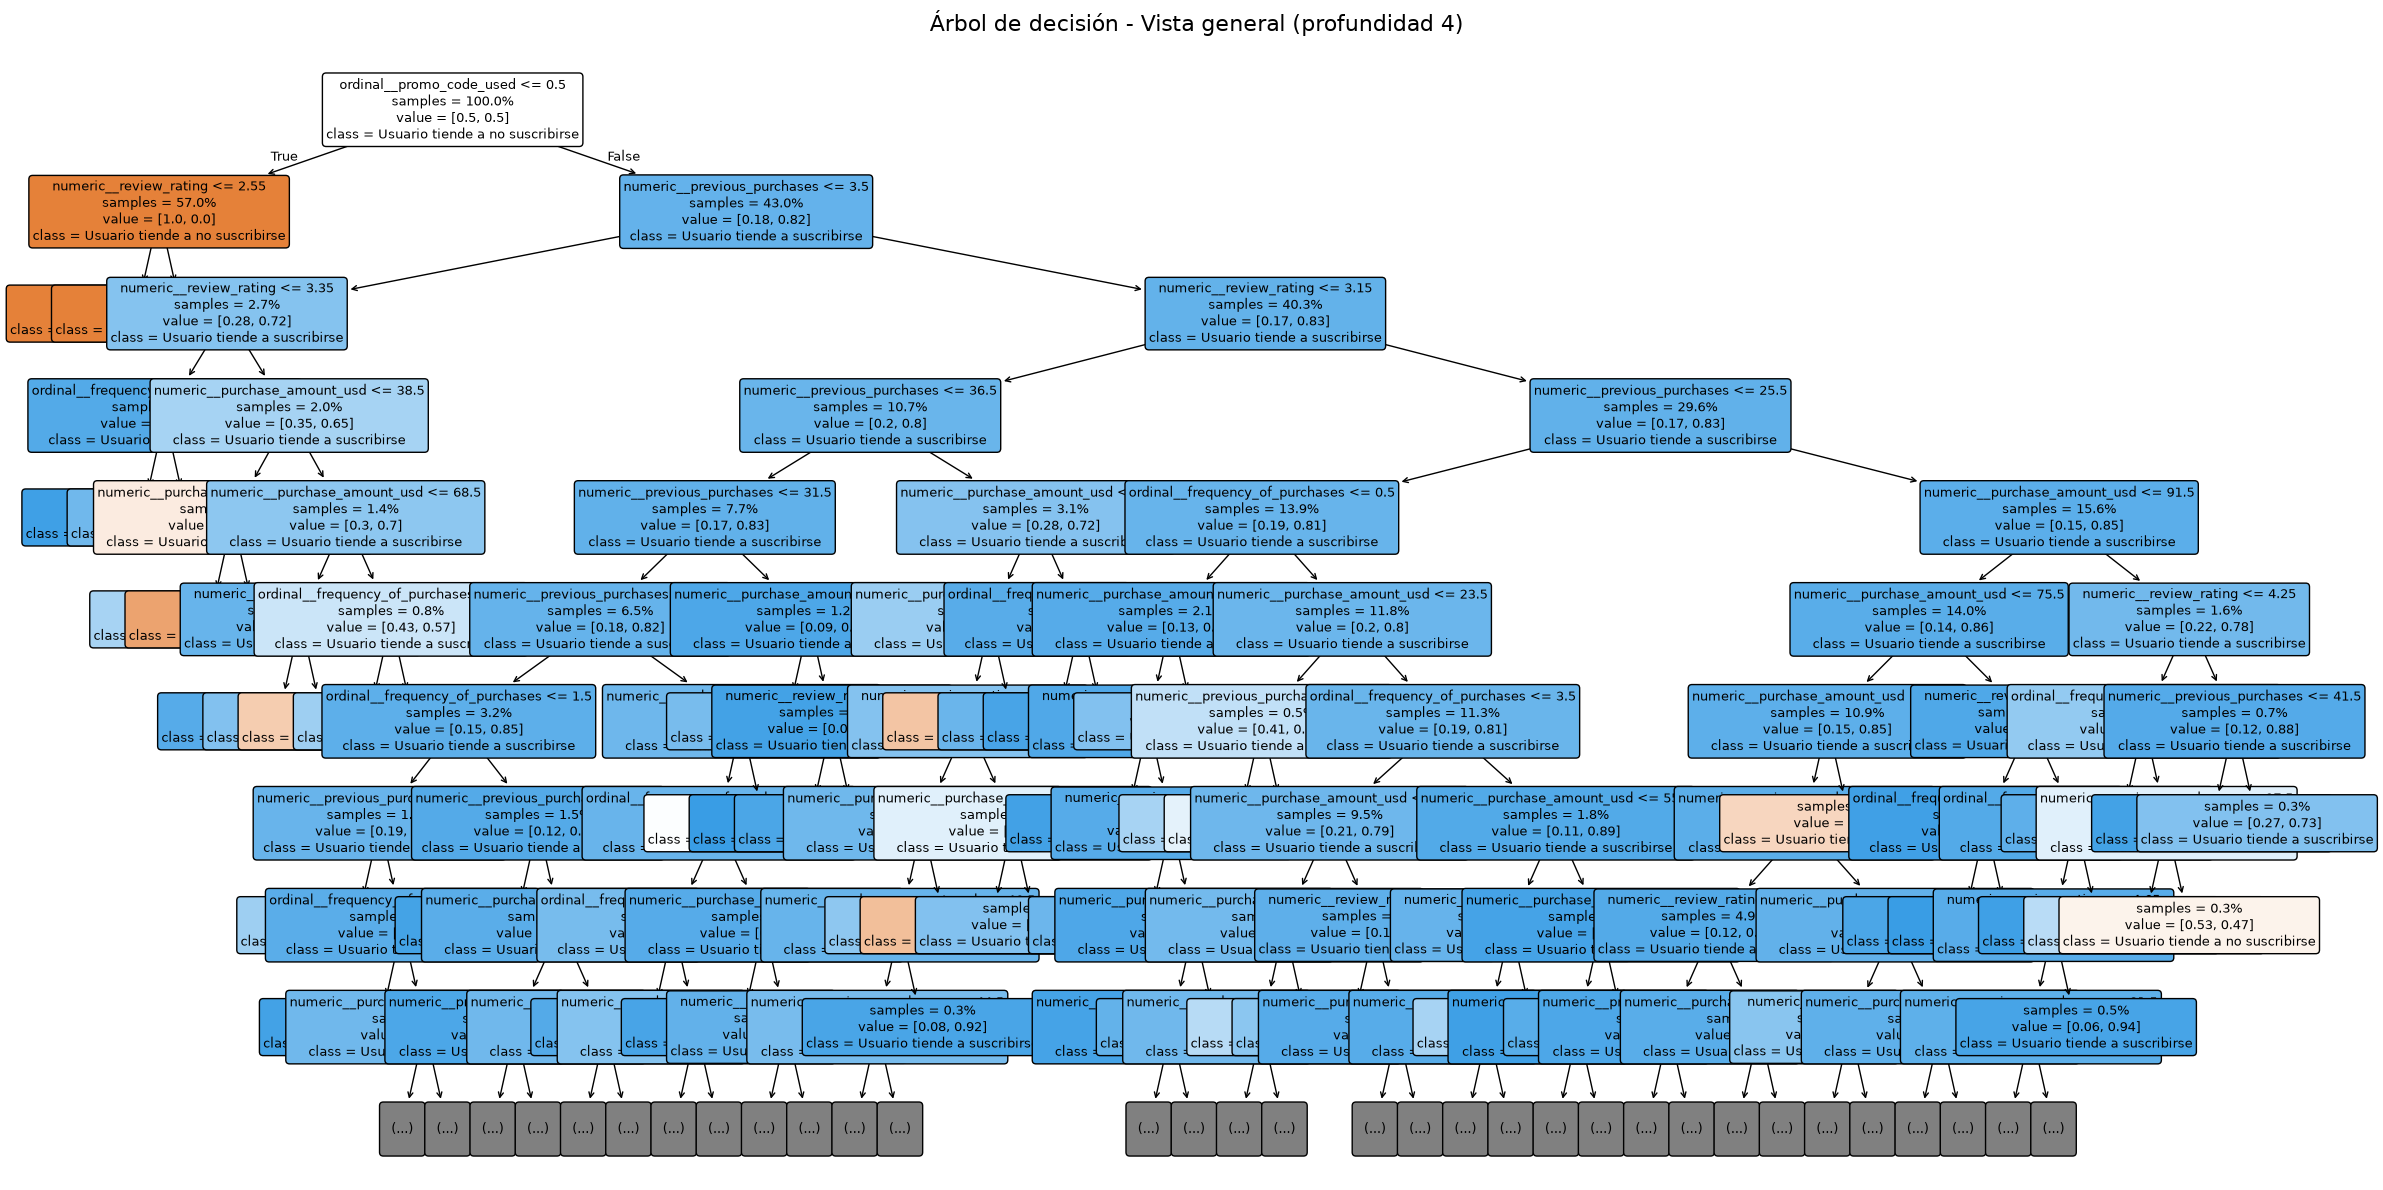

In [212]:
# Crear la figura
fig, ax = plt.subplots(figsize=(24, 12))

plot_tree(
    decision_tree_sin_reduccion,
    max_depth=9,  # Mostrar solo los primeros niveles
    filled=True,
    rounded=True,
    feature_names=nombres_variables,
    class_names=nombre_clases,
    fontsize=9,
    proportion=True,
    precision=2,
    impurity=False,
    ax=ax
)

ax.set_title(
    "Árbol de decisión - Vista general (profundidad 4)",
    fontsize=16,
    pad=20
)

plt.tight_layout()

plt.show()

In [213]:
pd.DataFrame({'Columnas preprocesadas':nombres_variables, 'Importancia':decision_tree_sin_reduccion.feature_importances_}).sort_values(by='Importancia', ascending=False)#['Columnas preprocesadas']

,Columnas preprocesadas,Importancia
3,ordinal__promo_code_used,0.918354
0,numeric__purchase_amount_usd,0.037527
1,numeric__review_rating,0.019858
2,numeric__previous_purchases,0.013598
4,ordinal__frequency_of_purchases,0.010664


#### Elasticnet

In [215]:
best_models[('ElasticNet', 'Sin reducción')]

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('all_columns', GeneralPreprocessor()),
                                 ('by_data_type_columns',
                                  ColumnTransformer(sparse_threshold=0,
                                                    transformers=[('numeric',
                                                                   'passthrough',
                                                                   ['purchase_amount_usd',
                                                                    'review_rating',
                                                                    'previous_purchases']),
                                                                  ('ordinal',
                                                                   Pipeline(steps=[('encoder',
                                                                                    OrdinalEncoder(categories=[['no',
                                                                                                                'yes'],
                                                                                                               ['annually',
                                                                                                                'quarterly',
                                                                                                                'monthly',
                                                                                                                'bi-weekly',
                                                                                                                'weekly']],
                                                                                                   handle_unknown='use_encoded_value',
                                                                                                   unknown_value=-1))]),
                                                                   ['promo_code_used',
                                                                    'frequency_of_purchases'])]))])),
                ('reduction', 'passthrough'),
                ('model',
                 SGDClassifier(l1_ratio=0.2, loss='log_loss', max_iter=3000,
                               penalty='elasticnet', random_state=42))])

In [217]:
pipeline_elasticnet_sin_reduccion = best_models[('ElasticNet', 'Sin reducción')]

In [219]:
elasticnet_sin_reduccion = pipeline_elasticnet_sin_reduccion.named_steps['model']

##### Evaluación

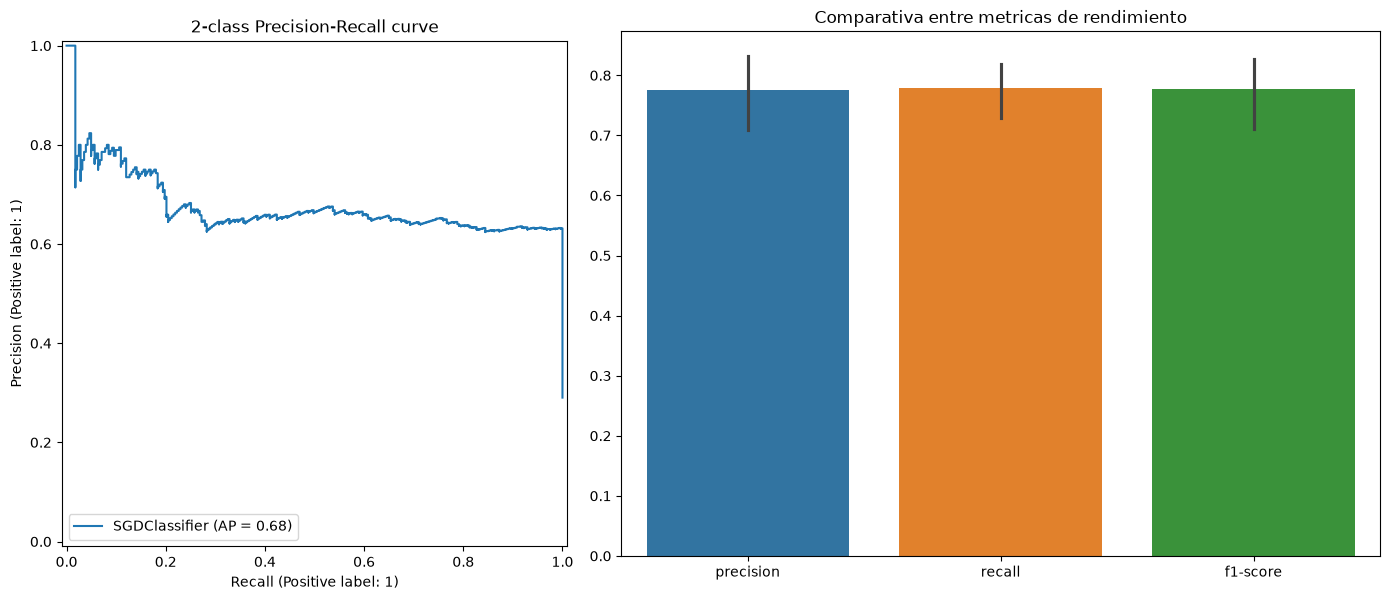

{'y_pred': array([0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1,
        0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1,
        0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0,
        0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0,
        0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0,
        0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0,
        1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
        1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0,
        0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
        1, 0, 0, 0, 0, 1, 0,

In [220]:
eval_model(model=elasticnet_sin_reduccion, is_classification=True, X=X_test, y=y_test)

##### Interpretavilidad

In [231]:
pd.DataFrame({'Columns':preprocessor.get_feature_names_out(), 'Coeficientes':elasticnet_sin_reduccion.coef_[0]}).sort_values(by=['Coeficientes'], ascending=False)

,Columns,Coeficientes
3,ordinal__promo_code_used,218.687082
1,numeric__review_rating,6.546954
4,ordinal__frequency_of_purchases,0.685702
2,numeric__previous_purchases,0.376215
0,numeric__purchase_amount_usd,0.000000


##### Hipotesis diagnosticas sobre variables asociadas a la suscripción

A partir de los resultados obtenidos en la primera iteración del modelado, se identificaron cinco variables relevantes para la segmentación de los clientes según su propensión a suscribirse: el uso de códigos promocionales, el monto de la compra, la valoración del producto (review_rating) y el número de compras previas, y el monto de compra hecho por el usuario (siendo esta ultima una relación aparentemente no lineal o bajo ciertos segmentos muy concretos, dado que el arbol le asigna una de las importancias mas altas, mientras que ElasticNet un coeficiente nulo).

Durante esta breve instancia de interpretabilidad diagnostica, el objetivo contrastar estas hipótesis mediante el análisis de las tasas de suscripción por grupos, la visualización de sus distribuciones y la comparación de las diferencias observadas. De este modo, se buscará determinar la dirección y magnitud de las asociaciones entre las variables seleccionadas y la suscripción, sin asumir de antemano que estas relaciones son crecientes ni que implican causalidad.




H1. Uso de códigos promocionales: la tasa de suscripción difiere entre los clientes que utilizan códigos promocionales y aquellos que no los utilizan.




Gráfico de barras que muestre el porcentaje de clientes suscritos en cada grupo, y intervalos de confianza del 95 % para mostrar la incertidumbre de las tasas estimadas.

Tabla de contingencia bivariada en mapa de calor

Prueba de independencia chi-cuadrado bivariada

H2. Numero de compras previas mayores, tienden a estar relacionadas con mayor probabilidad de subscripción

Gráfico de caja con numero de compras previas, separado por subscripción vs no subscripción

Test de Anova

H3. Montos de compras superiores, tienden a mayor subscripción

Gráfico de caja con numero de compras previas, separado por subscripción vs no subscripción

Test de Anova

Grafico de barras de la tasa de suscripción por intervalos de monto (bajo, medio-bajo, medio-alto, y alto) utilizando cuartiles de la distribución.

H4. Ratings mas altos, tienden a mayor tasa de subscripción

Gráfico de caja con numero de ratings, separado por subscripción vs no subscripción

Test de Anova

Grafico de barras de la tasa de suscripción por intervalos de rating (bajo, medio-bajo, medio-alto, y alto) utilizando cuartiles de la distribución.

H5. Usuarios con frecuencia de compras mas consecutivos en el tiempo, tienden a subscribirse mas

Gráfico de barras que muestre el porcentaje de clientes suscritos en cada grupo, y intervalos de confianza del 95 % para mostrar la incertidumbre de las tasas estimadas.

Tabla de contingencia bivariada en mapa de calor

Prueba de independencia chi-cuadrado bivariada

### Guardado del mejor modelo

In [214]:
# Guardar el modelo entrenado en un archivo .pkl
path_best_ml_model = '../models/subscription_status_decision_tree_base_model.pkl'
joblib.dump(decision_tree_sin_reduccion, path_best_ml_model)

['../models/subscription_status_decision_tree_base_model.pkl']